## Ejemplo 1: Regresión usando 1 sola neurona

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from tensorflow import keras
from tensorflow.keras import layers

### Generación de datos para el modelo

Se utilizará el modelo $y = 5x-2+v$, donde $v$ es ruido Gaussiano


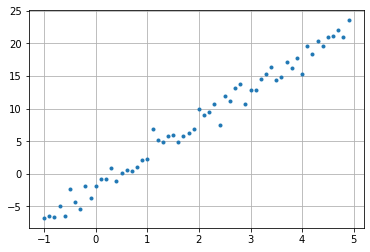

In [2]:
# Datos para el modelo
X = np.arange(-1, 5, 0.1)
# Ruido
v = np.random.randn(X.shape[0])*1.2
# Datos generados
y = 5*X-2 + v

# Gráfico de los datos de entrada
plt.plot(X, y, '.'), plt.grid();

### Red Neuronal

Creación de una red neuronal con:
* 1 neurona (1 unit)
* Función de activación lineal (por defecto)
* Entrada con 1 solo atributo (input_shape), ya que $X$ tiene dimensión 1

In [3]:
model = keras.Sequential([
            layers.Dense(units=1, input_shape=[1])
])

Creación del optimizador
* Optimizador: Stochastic Gradient Descent (sgd)
* Costo (loss): MSE (Mean Squared Error)

In [4]:
model.compile(optimizer='sgd', loss='mse')     # otra alternativa: loss='mse'

# Equivalentemente se podría usar: 
# model.compile(optimizer='sgd', loss='mean_squared_error')

Entrenamiento de la red neuronal, con 200 pasadas a todos los datos (epochs). Si verbose es `True`, muestra información mientras se entrena

In [5]:
history = model.fit(X, y, epochs=200, verbose=False);

Función de costo o pérdida

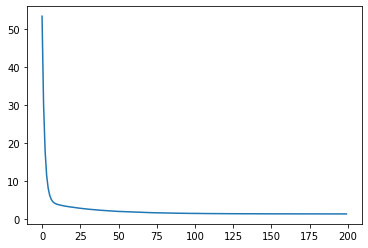

In [6]:
plt.plot(history.history['loss']);

In [7]:
# Pesos de la regresión
w, b = model.weights

# w tiene 1 sola dimensión, porque x tiene 1 sola dimensión
print("Pesos:\n{}\n\nBias\n{}".format(w, b))

Pesos:
<tf.Variable 'dense/kernel:0' shape=(1, 1) dtype=float32, numpy=array([[4.9800944]], dtype=float32)>

Bias
<tf.Variable 'dense/bias:0' shape=(1,) dtype=float32, numpy=array([-1.8608954], dtype=float32)>


### Predicción

In [8]:
xpred = [3.0, 5.0, 8.0]
ypred = model.predict(xpred)     # Valores que se predice

print("Valores que se predice:", ypred.T)

Valores que se predice: [[13.079388 23.039577 37.97986 ]]


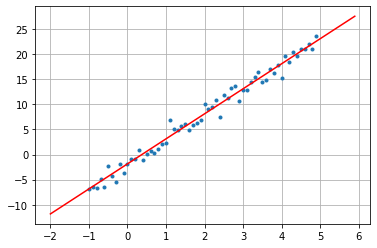

In [9]:
# Gráfico de los que se predice (en rojo) vs los datos de entrenamiento (en azul)
xpred_full = np.arange(-2, 6, 0.1)
ypred_full = model.predict(xpred_full)

plt.plot(X, y, '.'), plt.grid();
plt.plot(xpred_full, ypred_full, 'r');